# Tema 2 Machine Learning - Sentiment Analysis
## Mandescu Victor-Ioan 342C4

In [1]:
%pip install tensorflow
%pip install matplotlib Pillow scikit-learn seaborn spacy gensim nltk pandas tqdm
%pip install fasttext
!python -m spacy download ro_core_news_sm

import numpy as np
import os
import matplotlib.pyplot as plt
import random
import seaborn as sns
import spacy
import gensim
import string
import re
import pandas as pd
import nltk

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D
from tensorflow.keras.initializers import Constant
from tensorflow.keras.optimizers import Adam

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split

from collections import defaultdict, Counter
from tqdm import tqdm

from nltk.corpus import stopwords
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

  Using cached gensim-4.4.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (8.4 kB)
Using cached gensim-4.4.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (27.9 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 6.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.0.1-py3-none-any.whl.metadata (10.0 kB)
Using cached pybind11-3.0.1-py3-none-any.whl (293 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp312-cp312-linux_x86_64.whl size=4498211 sha256=ea34cdb2aa2da3ed75e7284444988f9eaab13c707302e93d9989b9b7736a76b2
  Stored in directory: /root/.cache/pip/wheels/20/27/95/a7baf1b435f1cbde017cabdf1e9688526d2b0e929255a359c6
Successfully built fasttext
  Using cached https://github.com/explosion/spacy-models/releases/download/ro_core_news_sm-3.8.0/ro_core_news_sm-3.8.0-py3-none-any.whl (12.9 MB)
✔ Download and

In [2]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

plt.style.use('ggplot')

stop = set(stopwords.words('english'))

try:
    stop = set(stopwords.words('romanian'))
    print("Stopwords pentru limba română încărcate din NLTK.")
except OSError:
    print("Eroare la încărcarea stopwords NLTK. Se vor folosi cele din SpaCy.")
    stop = set()

try:
    nlp = spacy.load("ro_core_news_sm")
    print("Modelul SpaCy 'ro_core_news_sm' a fost încărcat cu succes.")
    stop.update(nlp.Defaults.stop_words)
except OSError:
    print("ATENȚIE: Modelul SpaCy nu a putut fi încărcat. Asigură-te că ai rulat '!python -m spacy download ro_core_news_sm'")

print("\nMediul este pregătit pentru analiza sentimentelor pe text în limba română!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


Stopwords pentru limba română încărcate din NLTK.
Modelul SpaCy 'ro_core_news_sm' a fost încărcat cu succes.

Mediul este pregătit pentru analiza sentimentelor pe text în limba română!


## 1. Exploratory Data Analysis

In [3]:
print(stopwords.words('romanian'))

['a', 'abia', 'acea', 'aceasta', 'această', 'aceea', 'aceeasi', 'acei', 'aceia', 'acel', 'acela', 'acelasi', 'acele', 'acelea', 'acest', 'acesta', 'aceste', 'acestea', 'acestei', 'acestia', 'acestui', 'aceşti', 'aceştia', 'adica', 'ai', 'aia', 'aibă', 'aici', 'al', 'ala', 'ale', 'alea', 'alt', 'alta', 'altceva', 'altcineva', 'alte', 'altfel', 'alti', 'altii', 'altul', 'am', 'anume', 'apoi', 'ar', 'are', 'as', 'asa', 'asta', 'astea', 'astfel', 'asupra', 'atare', 'atat', 'atata', 'atatea', 'atatia', 'ati', 'atit', 'atita', 'atitea', 'atitia', 'atunci', 'au', 'avea', 'avem', 'aveţi', 'avut', 'aş', 'aţi', 'ba', 'ca', 'cam', 'cand', 'care', 'careia', 'carora', 'caruia', 'cat', 'catre', 'ce', 'cea', 'ceea', 'cei', 'ceilalti', 'cel', 'cele', 'celor', 'ceva', 'chiar', 'ci', 'cind', 'cine', 'cineva', 'cit', 'cita', 'cite', 'citeva', 'citi', 'citiva', 'cu', 'cui', 'cum', 'cumva', 'cât', 'câte', 'câtva', 'câţi', 'cînd', 'cît', 'cîte', 'cîtva', 'cîţi', 'că', 'căci', 'cărei', 'căror', 'cărui', 'căt

In [4]:
train_loader = pd.read_csv('train.csv')
test_loader = pd.read_csv('test.csv')

In [5]:
train_loader.head()

,index,text,label
0,0,acest document mi-a deschis cu adevarat ochii ...,1
1,1,tine mancarea rece. ce altceva ii mai trebuie?...,1
2,2,excelent\nrecomand!,1
3,3,"ca un rocker imbatranit, acest film mentioneaz...",1
4,4,"ei bine, a facut o groaza veche si foarte intu...",1


In [6]:
test_loader.head()

,Unnamed: 0,text,label
0,0,am vazut recent episoadele 1-4 si acum nu pot ...,1
1,1,anii cei mai buni ai vietii noastre capteaza p...,1
2,2,"aceasta apartine in clasa lor superioara, desi...",1
3,3,lucrare stralucitoare. actorii minunati se diz...,1
4,4,oamenii par sa se astepte la citizen kane aici...,1


In [7]:
test_loader.rename(columns={test_loader.columns[0]: 'index'}, inplace=True)
test_loader.head()

,index,text,label
0,0,am vazut recent episoadele 1-4 si acum nu pot ...,1
1,1,anii cei mai buni ai vietii noastre capteaza p...,1
2,2,"aceasta apartine in clasa lor superioara, desi...",1
3,3,lucrare stralucitoare. actorii minunati se diz...,1
4,4,oamenii par sa se astepte la citizen kane aici...,1


In [8]:
train_loader.shape

(17941, 3)

In [9]:
test_loader.shape

(11005, 3)

In [10]:
train_loader.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17941 entries, 0 to 17940
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   17941 non-null  int64 
 1   text    17651 non-null  object
 2   label   17941 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 420.6+ KB


In [11]:
test_loader.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11005 entries, 0 to 11004
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   11005 non-null  int64 
 1   text    11005 non-null  object
 2   label   11005 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 258.1+ KB


In [12]:
train_loader.isnull().sum()

,0
index,0
text,290
label,0


In [13]:
test_loader.isnull().sum()

,0
index,0
text,0
label,0


In [14]:
train_loader.dropna(subset=['text'], inplace=True)
train_loader.isnull().sum()

,0
index,0
text,0
label,0


In [15]:
train_loader.duplicated().sum()

np.int64(0)

In [16]:
test_loader.duplicated().sum()

np.int64(0)

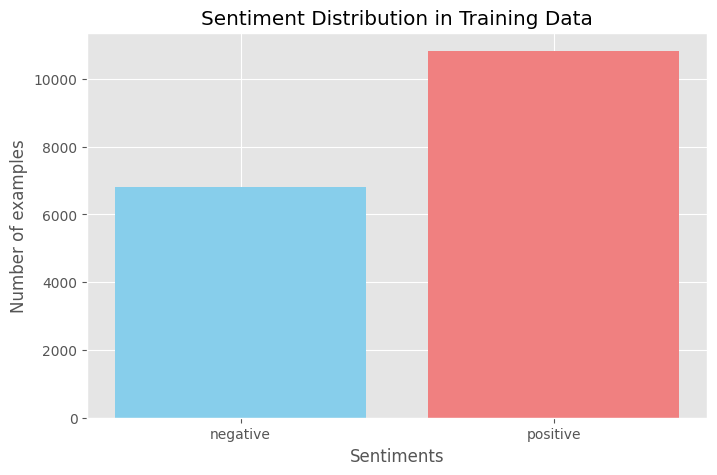

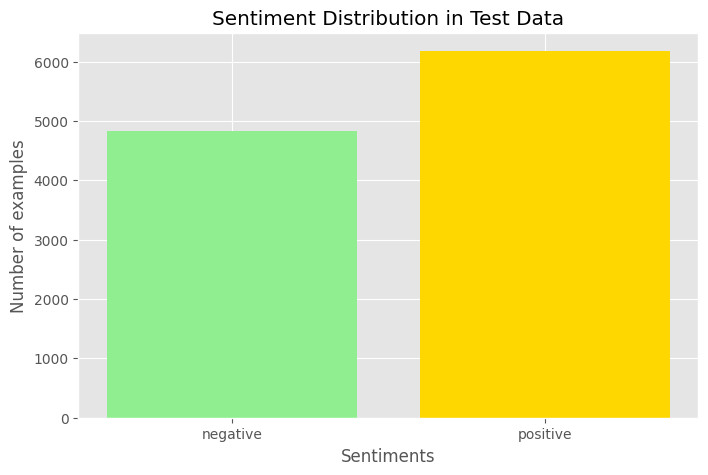

In [17]:
labels = ["negative", "positive"]
values_train = train_loader['label'].value_counts().sort_index().values
values_test = test_loader['label'].value_counts().sort_index().values

plt.figure(figsize=(8, 5))
plt.bar(labels, values_train, color=['skyblue', 'lightcoral'])
plt.xlabel('Sentiments')
plt.ylabel('Number of examples')
plt.title('Sentiment Distribution in Training Data')
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(labels, values_test, color=['lightgreen', 'gold'])
plt.xlabel('Sentiments')
plt.ylabel('Number of examples')
plt.title('Sentiment Distribution in Test Data')
plt.show()

In [18]:
from collections import Counter

pos_counter = Counter()
neg_counter = Counter()

for text in train_loader[train_loader['label'] == 1]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop and word.isalpha():
            clean_words.append(word)

    pos_counter.update(clean_words)

for text in train_loader[train_loader['label'] == 0]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop and word.isalpha():
            clean_words.append(word)

    neg_counter.update(clean_words)

print(pos_counter.most_common(10))
print(neg_counter.most_common(10))


[('film', 7712), ('filmul', 2231), ('vazut', 2093), ('bun', 1990), ('excelent', 1351), ('filme', 1280), ('recomand', 1250), ('trebuie', 1154), ('cred', 1107), ('facut', 1057)]
[('film', 6887), ('filmul', 1981), ('rau', 1525), ('vazut', 1471), ('lucru', 1415), ('decat', 1207), ('filme', 1185), ('facut', 1124), ('exista', 1045), ('cred', 1011)]


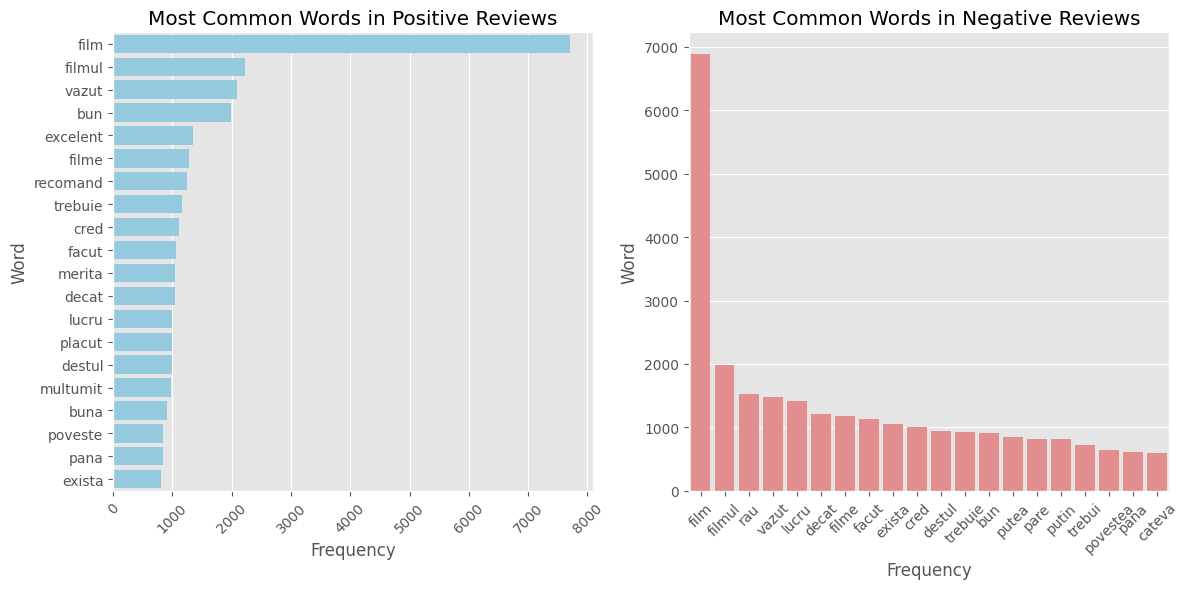

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

common_pos = pos_counter.most_common(20)
common_neg = neg_counter.most_common(20)

sns.barplot(x=[x[1] for x in common_pos], y=[x[0] for x in common_pos], ax=ax[0], color='skyblue')
ax[0].set_title('Most Common Words in Positive Reviews')
ax[0].set_xlabel('Frequency')
ax[0].set_ylabel('Word')
ax[0].tick_params(axis='x', labelrotation=45)

sns.barplot(x=[x[0] for x in common_neg], y=[x[1] for x in common_neg], ax=ax[1], color='lightcoral')
ax[1].set_title('Most Common Words in Negative Reviews')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Word')
ax[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()


In [20]:
pos_counter = Counter()
neg_counter = Counter()

for text in test_loader[test_loader['label'] == 1]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop and word.isalpha():
            clean_words.append(word)

    pos_counter.update(clean_words)

for text in test_loader[test_loader['label'] == 0]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop and word.isalpha():
            clean_words.append(word)

    neg_counter.update(clean_words)

print(pos_counter.most_common(10))
print(neg_counter.most_common(10))

[('film', 6608), ('filmul', 1824), ('vazut', 1613), ('filme', 1072), ('bun', 1058), ('trebuie', 1030), ('lucru', 1009), ('cred', 905), ('decat', 880), ('facut', 877)]
[('film', 6341), ('filmul', 1551), ('rau', 1425), ('lucru', 1335), ('vazut', 1219), ('filme', 1006), ('decat', 999), ('exista', 985), ('facut', 969), ('trebuie', 854)]


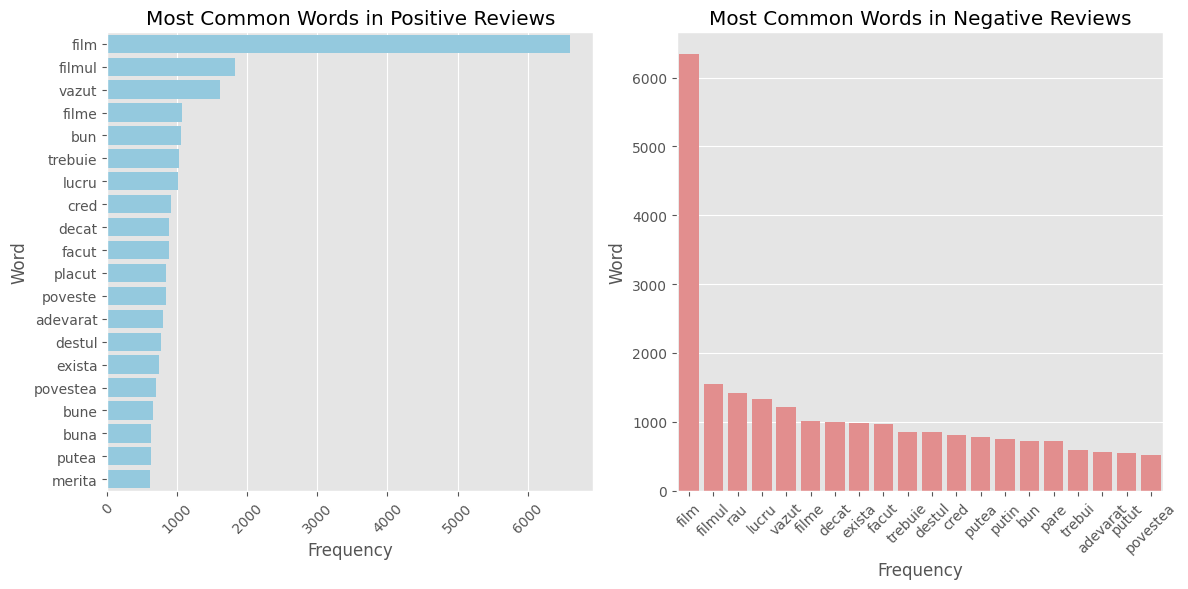

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

common_pos = pos_counter.most_common(20)
common_neg = neg_counter.most_common(20)

sns.barplot(x=[x[1] for x in common_pos], y=[x[0] for x in common_pos], ax=ax[0], color='skyblue')
ax[0].set_title('Most Common Words in Positive Reviews')
ax[0].set_xlabel('Frequency')
ax[0].set_ylabel('Word')
ax[0].tick_params(axis='x', labelrotation=45)

sns.barplot(x=[x[0] for x in common_neg], y=[x[1] for x in common_neg], ax=ax[1], color='lightcoral')
ax[1].set_title('Most Common Words in Negative Reviews')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Word')
ax[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

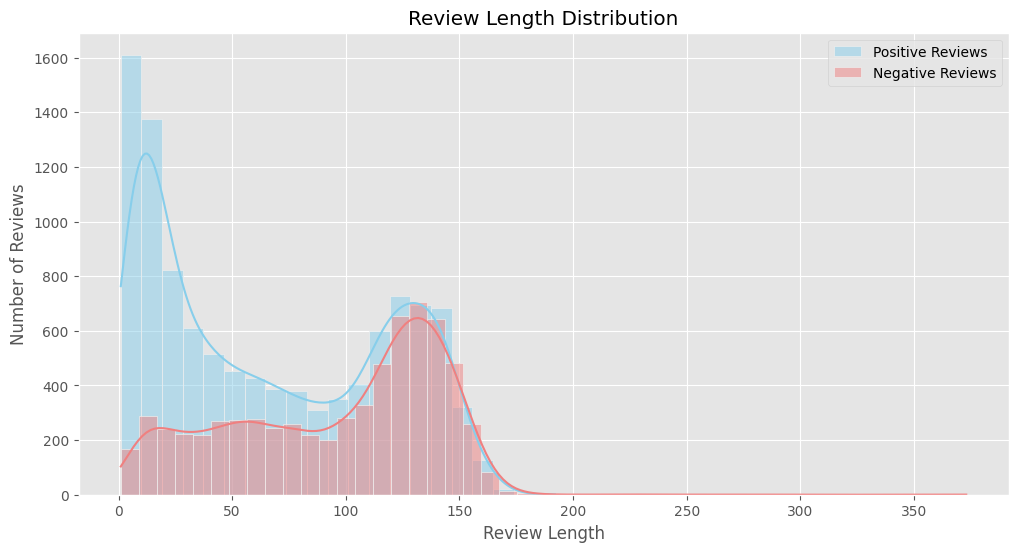

In [22]:
pos_counter = Counter()
neg_counter = Counter()

for text in train_loader[train_loader['label'] == 1]['text'].fillna(''):
  length = len(text.split())
  pos_counter.update([length])

for text in train_loader[train_loader['label'] == 0]['text'].fillna(''):
  length = len(text.split())
  neg_counter.update([length])

pos_lengths = list(pos_counter.elements())
neg_lengths = list(neg_counter.elements())

plt.figure(figsize=(12, 6))

sns.histplot(pos_lengths, color='skyblue', label='Positive Reviews', kde=True)
sns.histplot(neg_lengths, color='lightcoral', label='Negative Reviews', kde=True)

plt.title('Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Number of Reviews')
plt.legend()

plt.show()

## 2. Tokenize and Embedding

In [23]:
import re
from nltk.corpus import stopwords

stop_words = set(stopwords.words('romanian'))

def clean_text(dataset, text_field, new_text_field_name):
    dataset[new_text_field_name] = dataset[text_field].str.lower()
    dataset[new_text_field_name] = dataset[new_text_field_name].apply(lambda elem: re.sub(r"\d+", "", str(elem)))
    dataset[new_text_field_name] = dataset[new_text_field_name].apply(lambda elem: re.sub(r"[^a-z\săâîșț]", "", elem))
    dataset[new_text_field_name] = dataset[new_text_field_name].apply(lambda elem: " ".join([word for word in elem.split() if word not in stop_words]))
    return dataset

train_loader = clean_text(train_loader, 'text', 'text_clean')
test_loader = clean_text(test_loader, 'text', 'text_clean')

print(train_loader[['text', 'text_clean']].head())

                                                text  \
0  acest document mi-a deschis cu adevarat ochii ...   
1  tine mancarea rece. ce altceva ii mai trebuie?...   
2                                excelent\nrecomand!   
3  ca un rocker imbatranit, acest film mentioneaz...   
4  ei bine, a facut o groaza veche si foarte intu...   

                                          text_clean  
0  document mia deschis adevarat ochii oamenii af...  
1  mancarea rece trebuie frigiderul an utilizare ...  
2                                  excelent recomand  
3  rocker imbatranit film mentioneaza heep and qu...  
4  bine facut groaza veche intunecata casa setare...  


In [24]:
import spacy
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Încărcăm modelul SpaCy (dacă nu e deja încărcat)
try:
    nlp = spacy.load("ro_core_news_sm")
    # Dezactivăm componentele inutile pentru viteză (avem nevoie doar de tokenizer)
    nlp.disable_pipes(["parser", "ner"])
    print("SpaCy încărcat cu succes.")
except:
    print("Modelul SpaCy nu a putut fi încărcat! Asigură-te că ai rulat '!python -m spacy download ro_core_news_sm'")

def tokenize(text_field):
    tokenized_list = []
    for doc in nlp.pipe(text_field.astype(str), batch_size=1000):
      tokens = [token.text for token in doc if not token.is_space]
      tokenized_list.append(tokens)
    return tokenized_list

train_loader['tokens'] = tokenize(train_loader['text_clean'])
test_loader['tokens'] = tokenize(test_loader['text_clean'])

print(train_loader[['text_clean', 'tokens']].head())

SpaCy încărcat cu succes.
                                          text_clean  \
0  document mia deschis adevarat ochii oamenii af...   
1  mancarea rece trebuie frigiderul an utilizare ...   
2                                  excelent recomand   
3  rocker imbatranit film mentioneaza heep and qu...   
4  bine facut groaza veche intunecata casa setare...   

                                              tokens  
0  [document, mia, deschis, adevarat, ochii, oame...  
1  [mancarea, rece, trebuie, frigiderul, an, util...  
2                               [excelent, recomand]  
3  [rocker, imbatranit, film, mentioneaza, heep, ...  
4  [bine, facut, groaza, veche, intunecata, casa,...  


In [25]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB_SIZE = 20000
MAX_SEQUENCE_LENGTH = 100

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_loader['tokens'])

X_train_seq = tokenizer.texts_to_sequences(train_loader['tokens'])
X_test_seq = tokenizer.texts_to_sequences(test_loader['tokens'])

X_train = pad_sequences(X_train_seq, maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')
X_test = pad_sequences(X_test_seq, maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

word_index = tokenizer.word_index
print(f"Mărime vocabular: {len(word_index)}")
print(f"Exemplu indici: {X_train[0][:10]}")

Mărime vocabular: 58135
Exemplu indici: [4799   22 1259   29  507   88  165 8928 2843  245]


In [26]:
# Rulează asta o singură dată pentru a descărca vectorii (durează puțin, are ~1GB arhivat)
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ro.300.vec.gz
!gunzip cc.ro.300.vec.gz

--2026-01-05 14:52:19--  https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ro.300.vec.gz
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.35.37.123, 13.35.37.111, 13.35.37.84, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.35.37.123|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1233659733 (1.1G) [binary/octet-stream]
Saving to: ‘cc.ro.300.vec.gz’

cc.ro.300.vec.gz    100%[===================>]   1.15G   171MB/s    in 6.9s    

2026-01-05 14:52:26 (171 MB/s) - ‘cc.ro.300.vec.gz’ saved [1233659733/1233659733]



In [27]:
# Calea către fișierul descărcat
EMBEDDING_FILE = 'cc.ro.300.vec'
EMBEDDING_DIM = 300 # FastText are vectori de dimensiune 300

# 1. Citim fișierul FastText și creăm un dicționar Cuvânt -> Vector
embeddings_index = {}
print("Se încarcă vectorii FastText (aveți răbdare)...")

with open(EMBEDDING_FILE, 'r', encoding='utf-8', newline='\n', errors='ignore') as f:
    next(f) # Sărim peste prima linie (header)
    for line in f:
        values = line.rstrip().split(' ')
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs

print(f'S-au încărcat {len(embeddings_index)} vectori.')

# 2. Creăm Matricea de Embedding (Harta Vocabularul Tău -> FastText)
# Această matrice va intra în rețeaua neurală
num_words = min(MAX_VOCAB_SIZE, len(word_index) + 1)
embedding_matrix = np.zeros((num_words, EMBEDDING_DIM))
hits = 0
misses = 0

for word, i in word_index.items():
    if i >= MAX_VOCAB_SIZE:
        continue
    embedding_vector = embeddings_index.get(word)
    if embedding_vector is not None:
        # Cuvântul există în FastText
        embedding_matrix[i] = embedding_vector
        hits += 1
    else:
        # Cuvântul nu există (rămâne zero)
        misses += 1

print(f"Am găsit vectori pentru {hits} cuvinte. Lipsesc {misses}.")

Se încarcă vectorii FastText (aveți răbdare)...
S-au încărcat 2000000 vectori.
Am găsit vectori pentru 18205 cuvinte. Lipsesc 1794.


In [28]:
from tensorflow.keras.layers import Embedding

embedding_layer = Embedding(
    input_dim=num_words,
    output_dim=EMBEDDING_DIM,
    embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
    input_length=MAX_SEQUENCE_LENGTH,
    trainable=False # Important: Înghețăm vectorii ca să nu se strice la antrenare
)

print("Embedding Layer pregătit!")

Embedding Layer pregătit!


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

# 1. Pregătim etichetele (y)
# Asigură-te că coloana cu sentimentul se numește 'label' (sau 'sentiment' - verifică în df-ul tău)
y_train = train_loader['label'].values
y_test = test_loader['label'].values

# 2. Construim Modelul RNN Simplu
model_rnn = Sequential()

# Adăugăm stratul de Embedding creat anterior (FastText)
# Acesta transformă numerele în vectori deștepți
model_rnn.add(embedding_layer)

# Adăugăm stratul RNN Simplu
# 64 este numărul de neuroni (hidden state size) - poți experimenta cu 32, 64, 128
model_rnn.add(SimpleRNN(64, return_sequences=False))

# (Opțional) Dropout ajută la prevenirea overfitting-ului
model_rnn.add(Dropout(0.5))

# Stratul final de clasificare (1 neuron pentru că e binar: Pozitiv/Negativ)
# Sigmoid scoate un număr între 0 și 1
model_rnn.add(Dense(1, activation='sigmoid'))

# 3. Compilăm modelul
model_rnn.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

# Afișăm rezumatul arhitecturii
model_rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Clasele detectate: [0 1]
Exemplu conversie: 1 -> 1
Epoch 1/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.5948 - loss: 0.6711 - val_accuracy: 0.5614 - val_loss: 0.6863
Epoch 2/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.6139 - loss: 0.6657 - val_accuracy: 0.5613 - val_loss: 0.6917
Epoch 3/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6132 - loss: 0.6663 - val_accuracy: 0.5613 - val_loss: 0.6902
Epoch 4/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.5845 - loss: 0.6848 - val_accuracy: 0.5613 - val_loss: 0.6956
Epoch 5/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6048 - loss: 0.6710 - val_accuracy: 0.5613 - val_loss: 0.6910
Epoch 6/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.6142 - loss: 0.6672 - val_accuracy: 0.5613 - val_loss: 0.6908
Epoch 7/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.6045 - loss: 0.6709 - val_accuracy: 0.5613 - val_loss: 0.6922
Epoch 8/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 6s 12

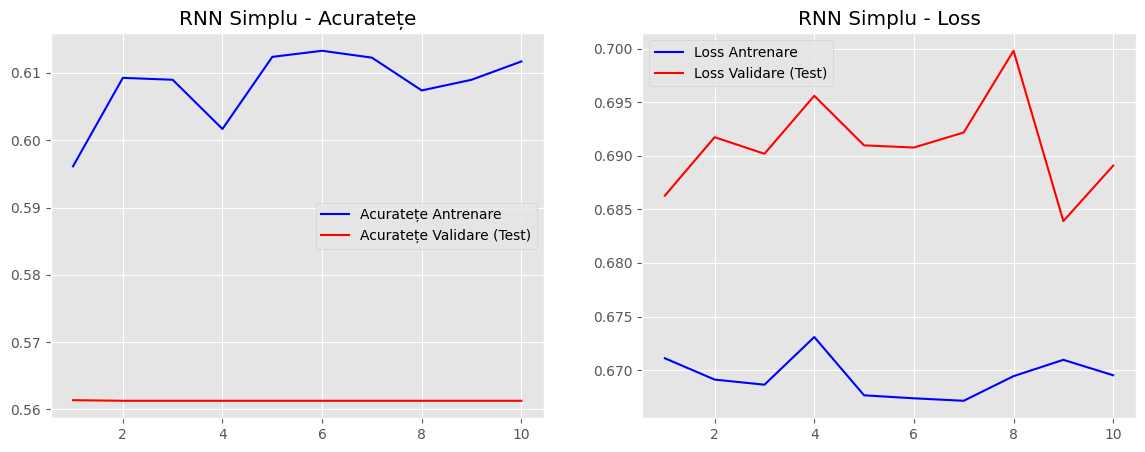

In [30]:
from sklearn.preprocessing import LabelEncoder

# Convertim etichetele din text ('positive', 'negative') în numere (1, 0)
encoder = LabelEncoder()
y_train = encoder.fit_transform(train_loader['label'])
y_test = encoder.transform(test_loader['label'])

print(f"Clasele detectate: {encoder.classes_}")
print(f"Exemplu conversie: {train_loader['label'].iloc[0]} -> {y_train[0]}")

# Configurăm antrenarea
history_rnn = model_rnn.fit(
    X_train, y_train,                    # Datele de antrenare
    epochs=10,                           # De câte ori trece prin tot setul de date
    batch_size=32,                       # Câte exemple procesează deodată
    validation_data=(X_test, y_test),    # Testăm pe setul de test la finalul fiecărei epoci
    verbose=1                            # Afișăm bara de progres
)

import matplotlib.pyplot as plt

def plot_history(history, model_name="Model"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Grafic Acuratețe
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b', label='Acuratețe Antrenare')
    plt.plot(epochs, val_acc, 'r', label='Acuratețe Validare (Test)')
    plt.title(f'{model_name} - Acuratețe')
    plt.legend()

    # Grafic Loss (Eroare)
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b', label='Loss Antrenare')
    plt.plot(epochs, val_loss, 'r', label='Loss Validare (Test)')
    plt.title(f'{model_name} - Loss')
    plt.legend()

    plt.show()

plot_history(history_rnn, model_name="RNN Simplu")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 300)       │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 6,000,000 (22.89 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.6539 - loss: 0.6257 - val_accuracy: 0.7886 - val_loss: 0.4947
Epoch 2/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.8541 - loss: 0.3692 - val_accuracy: 0.8430 - val_loss: 0.3966
Epoch 3/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.8952 - loss: 0.3030 - val_accuracy: 0.8296 - val_loss: 0.4349
Epoch 4/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9309 - loss: 0.2076 - val_accuracy: 0.8405 - val_loss: 0.3863
Epoch 5/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9521 - loss: 0.1628 - val_accuracy: 0.8421 - val_loss: 0.4385
Epoch 6/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9574 - loss: 0.1475 - val_accuracy: 0.8255 - val_loss: 0.5408
Epoch 7/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9647 - loss: 0.1204 - val_accuracy: 0.8311 - val_loss: 0.5130
Epoch 8/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9716 - loss: 0.1019 - 

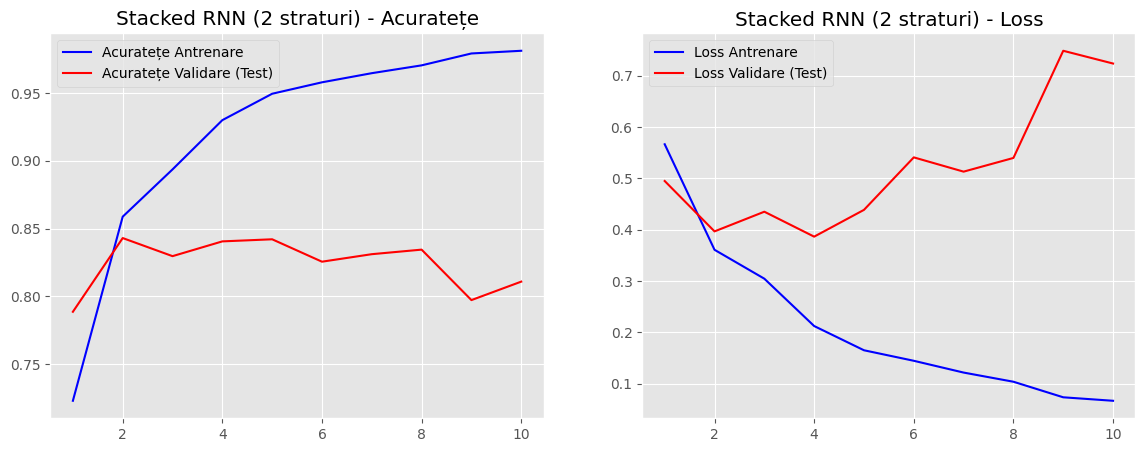

In [31]:
# === Experiment: RNN cu 2 straturi + Embedding Antrenabil ===
model_rnn_v2 = Sequential()

# 1. Embedding - Îl facem antrenabil (trainable=True)
# Asta permite modelului să ajusteze vectorii FastText pentru recenzii
embedding_layer.trainable = True
model_rnn_v2.add(embedding_layer)

# 2. Primul strat RNN
# return_sequences=True este OBLIGATORIU dacă mai urmează un strat RNN
model_rnn_v2.add(SimpleRNN(128, return_sequences=True)) # Am crescut la 128 neuroni
model_rnn_v2.add(Dropout(0.3)) # Dropout mai mic

# 3. Al doilea strat RNN (experiment cu numărul de straturi)
model_rnn_v2.add(SimpleRNN(64, return_sequences=False)) # Ultimul strat nu returnează secvențe
model_rnn_v2.add(Dropout(0.3))

# 4. Clasificare
model_rnn_v2.add(Dense(1, activation='sigmoid'))

# Compilare cu un Learning Rate mai mic (pentru stabilitate)
opt = tf.keras.optimizers.Adam(learning_rate=0.0001)
model_rnn_v2.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

model_rnn_v2.summary()

# Antrenare
history_v2 = model_rnn_v2.fit(
    X_train, y_train,
    epochs=10, # Poți încerca 15 dacă vezi că începe să învețe
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# Afișare grafice pentru V2
plot_history(history_v2, model_name="Stacked RNN (2 straturi)")

In [32]:
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout

# 1. Inițializăm modelul
model_lstm = Sequential()

# 2. Adăugăm Embedding-ul (FastText)
# Îl lăsăm antrenabil pentru a se adapta la vocabularul specific recenziilor
embedding_layer.trainable = True
model_lstm.add(embedding_layer)

# 3. Primul strat LSTM - BIDIRECȚIONAL [Cerință: Bidirecționale]
# return_sequences=True este necesar pentru că urmează încă un strat LSTM
# 64 este dimensiunea hidden state-ului [Cerință: dimensiunea hidden state]
model_lstm.add(Bidirectional(LSTM(64, return_sequences=True)))
model_lstm.add(Dropout(0.3)) # Regularizare

# 4. Al doilea strat LSTM [Cerință: Numărul de straturi]
# Aici nu mai punem return_sequences=True, vrem doar rezultatul final
model_lstm.add(Bidirectional(LSTM(32)))
model_lstm.add(Dropout(0.3))

# 5. Straturi Liniare (Dense) [Cerință: Combinarea cu straturi liniare]
# Un strat intermediar pentru a procesa trăsăturile extrase de LSTM
model_lstm.add(Dense(64, activation='relu'))
model_lstm.add(Dropout(0.2))

# 6. Stratul final de ieșire (Sigmoid pentru clasificare binară 0/1)
model_lstm.add(Dense(1, activation='sigmoid'))

# Compilare
# Folosim un learning rate puțin mai mic pentru stabilitate
opt = tf.keras.optimizers.Adam(learning_rate=0.0001)
model_lstm.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

model_lstm.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 300)       │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 6,000,000 (22.89 MB)

 Non-trainable params: 0 (0.00 B)

Începem antrenarea LSTM...
Epoch 1/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.7207 - loss: 0.5188 - val_accuracy: 0.8373 - val_loss: 0.4781
Epoch 2/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.9668 - loss: 0.1121 - val_accuracy: 0.8424 - val_loss: 0.5303
Epoch 3/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.9811 - loss: 0.0689 - val_accuracy: 0.8410 - val_loss: 0.5881
Epoch 4/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9849 - loss: 0.0560 - val_accuracy: 0.8365 - val_loss: 0.6834
Epoch 5/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.9880 - loss: 0.0487 - val_accuracy: 0.8284 - val_loss: 0.7149
Epoch 6/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9871 - loss: 0.0490 - val_accuracy: 0.8373 - val_loss: 0.8213
Epoch 7/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.9895 - loss: 0.0395 - val_accuracy: 0.8175 - val_loss: 0.8617
Epoch 8/10
552/552 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - accurac

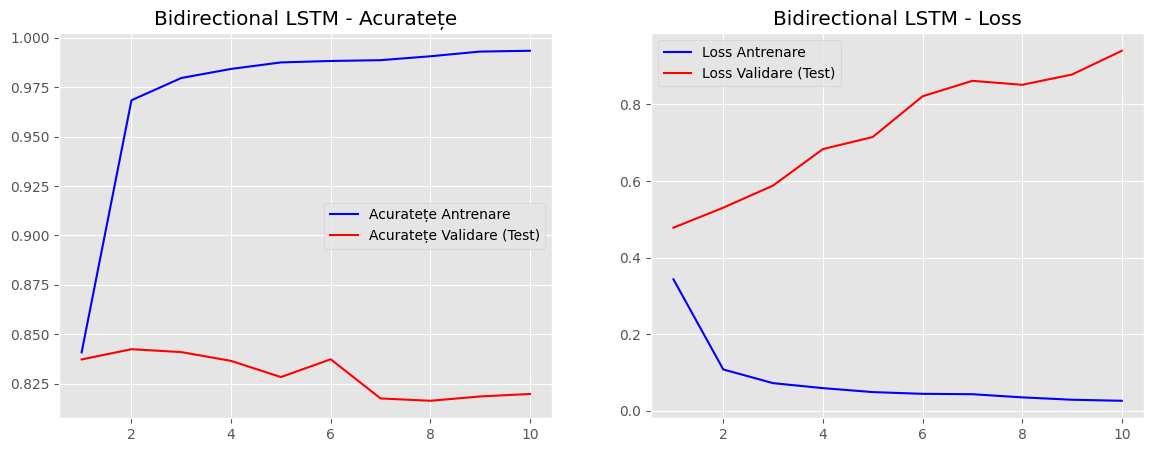

In [33]:
print("Începem antrenarea LSTM...")

history_lstm = model_lstm.fit(
    X_train, y_train,
    epochs=10,             # Poți crește la 15 dacă vezi că încă învață
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

plot_history(history_lstm, model_name="Bidirectional LSTM")

In [34]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Definim Modelul (cu Dropout mai agresiv)
model_lstm_opt = Sequential()
model_lstm_opt.add(embedding_layer) # FastText

# Dropout 0.4 în loc de 0.3 (mai agresiv)
model_lstm_opt.add(Bidirectional(LSTM(64, return_sequences=True)))
model_lstm_opt.add(Dropout(0.4))

model_lstm_opt.add(Bidirectional(LSTM(32)))
model_lstm_opt.add(Dropout(0.4))

model_lstm_opt.add(Dense(64, activation='relu'))
model_lstm_opt.add(Dropout(0.3))

model_lstm_opt.add(Dense(1, activation='sigmoid'))

# Folosim un learning rate mic pentru fine-tuning
opt = tf.keras.optimizers.Adam(learning_rate=0.0001)

model_lstm_opt.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

# 2. Definim Callbacks (Secretul împotriva Overfitting-ului)
callbacks = [
    # Oprește antrenarea dacă val_loss nu scade timp de 3 epoci
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),

    # Reduce Learning Rate-ul dacă modelul se blochează
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

print("Începem antrenarea optimizată...")
history_opt = model_lstm_opt.fit(
    X_train, y_train,
    epochs=15,  # Putem pune mai multe, EarlyStopping îl va opri oricum
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=callbacks, # Aici activăm "frânele"
    verbose=1
)

# 3. Vedem noul grafic
plot_history(history_opt, model_name="LSTM Optimizat (Early Stopping)")

Începem antrenarea optimizată...
Epoch 1/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.6936 - loss: 0.5407 - val_accuracy: 0.8362 - val_loss: 0.5670 - learning_rate: 1.0000e-04
Epoch 2/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9853 - loss: 0.0559 - val_accuracy: 0.8290 - val_loss: 0.7583 - learning_rate: 1.0000e-04
Epoch 3/15
462/552 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9904 - loss: 0.0361

KeyboardInterrupt: 